# 02 · A/B test: does the redesigned checkout convert better?

**Context.** The product team redesigned the checkout page (variant **B**: saved-address
autofill, one-page flow, add-on suggestions) and ran a 50/50 test against the current page
(variant **A**) for three weeks in September 2025. 40,000 users were exposed.

**Pre-registered plan (written before looking at results):**

| Item | Decision |
|---|---|
| Primary metric | Conversion rate (purchase / exposed user) |
| Secondary metrics | Revenue per exposed user; average order value among converters |
| Baseline | 3.1% (previous quarter) |
| Minimum detectable effect | +15% relative (3.1% → 3.57%) |
| α / power | 0.05 (two-sided) / 0.80 |
| Guardrails | Sample-ratio mismatch check; segment analysis is exploratory only |

**Data:** `data/raw/ab_test_checkout.csv` (synthetic, seeded).

In [2]:
import sys
sys.path.insert(0, ".")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from src.stats_utils import (two_proportion_ztest, sample_size_two_proportions, srm_check,
                             bootstrap_diff_ci)

plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.grid": True,
                     "grid.color": "#e1e0d9", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "axes.titleweight": "bold"})
BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#898781"

ab = pd.read_csv("data/raw/ab_test_checkout.csv", parse_dates=["exposure_date"])
ab.head()

,user_id,exposure_date,variant,user_type,device,converted,order_value,sessions
0,U500000,2025-09-11,A,new,mobile,0,0,2
1,U500001,2025-09-12,B,new,mobile,0,0,2
2,U500002,2025-09-14,A,returning,mobile,0,0,1
3,U500003,2025-09-09,B,new,desktop,0,0,1
4,U500004,2025-09-11,A,new,mobile,0,0,3


## 1. Was the test big enough? (power check against the pre-registered MDE)

In [4]:
n_needed = sample_size_two_proportions(p_base=0.031, mde_rel=0.15, alpha=0.05, power=0.80)
n_actual = ab["variant"].value_counts().min()
print(f"Per-group sample size needed for +15% relative lift at 80% power: {n_needed:,}")
print(f"Per-group sample size actually collected:                       {n_actual:,}")
print(f"Shortfall: {n_needed - n_actual:,} users per group  ->  the test is somewhat under-powered for the planned MDE.")

Per-group sample size needed for +15% relative lift at 80% power: 23,387
Per-group sample size actually collected:                       19,946
Shortfall: 3,441 users per group  ->  the test is somewhat under-powered for the planned MDE.


The test stopped at ~20k per group against a plan of ~23k. That does not invalidate anything,
but it means a *true* 15% lift would have been missed roughly one time in four, and any
estimate we get will carry a wide confidence interval. Worth knowing before reading the result.

## 2. Guardrail: sample-ratio mismatch
If randomisation is broken, nothing downstream is trustworthy.

In [7]:
counts = ab["variant"].value_counts().to_dict()
chi2, p_srm = srm_check(counts, {"A": 0.5, "B": 0.5})
print(f"Allocation: {counts}  |  chi² = {chi2:.3f}, p = {p_srm:.3f}")
print("SRM check passed - allocation is consistent with 50/50." if p_srm > 0.01 else "SRM FAILED - investigate assignment before reading results.")

Allocation: {'B': 20054, 'A': 19946}  |  chi² = 0.292, p = 0.589
SRM check passed - allocation is consistent with 50/50.


## 3. Primary metric: conversion rate

In [9]:
agg = ab.groupby("variant").agg(users=("user_id", "size"), conversions=("converted", "sum"))
agg["conversion_rate_%"] = 100 * agg["conversions"] / agg["users"]
primary = two_proportion_ztest(agg.loc["A", "conversions"], agg.loc["A", "users"],
                               agg.loc["B", "conversions"], agg.loc["B", "users"])
print(agg.round(3))
print(primary.summary())

         users  conversions  conversion_rate_%
variant                                       
A        19946          631              3.164
B        20054          735              3.665
control 3.164% vs treatment 3.665% | abs lift +0.502% (rel +15.9%) | 95% CI [+0.146%, +0.857%] | z = 2.76, p = 0.0058


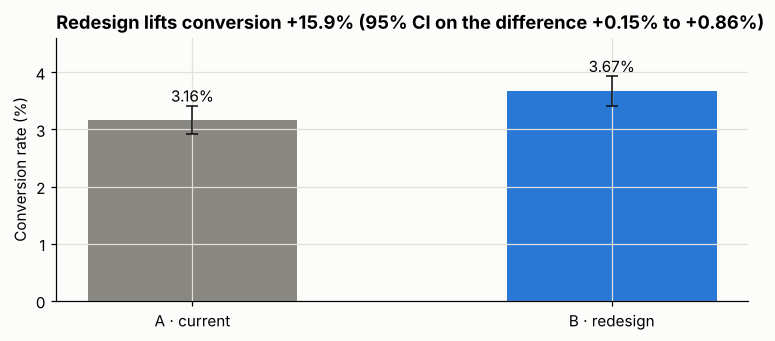

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(["A · current", "B · redesign"], [primary.p_control * 100, primary.p_treatment * 100], color=[MUTED, BLUE], width=0.5)
for i, v in enumerate([primary.p_control, primary.p_treatment]):
    n = agg["users"].iloc[i]
    se = 1.96 * np.sqrt(v * (1 - v) / n) * 100
    ax.errorbar(i, v * 100, yerr=se, color="#0b0b0b", capsize=4, lw=1)
    ax.text(i, v * 100 + se + 0.08, f"{v:.2%}", ha="center", fontsize=10)
ax.set_ylim(0, 4.6); ax.set_ylabel("Conversion rate (%)")
ax.set_title(f"Redesign lifts conversion {primary.rel_lift:+.1%} (95% CI on the difference {primary.ci_low:+.2%} to {primary.ci_high:+.2%})")
plt.tight_layout()

**Result:** B converts at 3.67% vs 3.16% — a **+0.50 pt absolute, +15.9% relative** lift,
z = 2.76, **p = 0.006**. The 95% CI on the absolute difference is **+0.15 to +0.86 pt**
(roughly +5% to +27% relative). Statistically clear; the interval is as wide as the power
check predicted.

## 4. Secondary metrics: revenue per user and basket size
Conversion can go up while basket goes down (people buy smaller things more easily). Check both.

In [13]:
rpu = ab.groupby("variant")["order_value"].mean()
lo, hi = bootstrap_diff_ci(ab.loc[ab.variant == "B", "order_value"], ab.loc[ab.variant == "A", "order_value"], n_boot=4000, seed=1)
print(f"Revenue per exposed user: A = {rpu['A']:,.0f} VND, B = {rpu['B']:,.0f} VND  ({rpu['B'] / rpu['A'] - 1:+.1%})")
print(f"Bootstrap 95% CI for B - A: [{lo:,.0f}, {hi:,.0f}] VND  -> excludes zero")

conv = ab[ab["converted"] == 1]
aov = conv.groupby("variant")["order_value"].agg(["mean", "median", "count"])
u = stats.mannwhitneyu(conv.loc[conv.variant == "B", "order_value"], conv.loc[conv.variant == "A", "order_value"])
print("\nAverage order value among converters:")
print(aov.round(0))
print(f"Mann-Whitney U (order values are right-skewed, so no t-test): p = {u.pvalue:.3f}")

Revenue per exposed user: A = 27,795 VND, B = 33,236 VND  (+19.6%)
Bootstrap 95% CI for B - A: [1,878, 9,041] VND  -> excludes zero

Average order value among converters:
             mean    median  count
variant                           
A        878612.0  782000.0    631
B        906831.0  786000.0    735
Mann-Whitney U (order values are right-skewed, so no t-test): p = 0.224


Revenue per user rises **~+20%**, and the bootstrap interval excludes zero. Basket size among
converters is **not** significantly different (p ≈ 0.22): the add-on suggestions did not move
AOV. The revenue gain is a conversion gain, nothing more and nothing less.

## 5. Exploratory: who is the lift coming from?
Four pre-defined segments. Because this is exploratory and there are four tests, the bar for
"interesting" is Bonferroni-adjusted: p < 0.0125.

In [16]:
rows = []
for col in ["user_type", "device"]:
    for level, g in ab.groupby(col):
        s = g.groupby("variant").agg(n=("user_id", "size"), x=("converted", "sum"))
        r = two_proportion_ztest(s.loc["A", "x"], s.loc["A", "n"], s.loc["B", "x"], s.loc["B", "n"])
        rows.append({"segment": f"{col} = {level}", "users": int(s["n"].sum()), "cr_A_%": 100 * r.p_control,
                     "cr_B_%": 100 * r.p_treatment, "rel_lift_%": 100 * r.rel_lift,
                     "ci_low_pt": 100 * r.ci_low, "ci_high_pt": 100 * r.ci_high, "p_value": r.p_value})
seg = pd.DataFrame(rows).set_index("segment")
seg["significant_(Bonferroni)"] = seg["p_value"] < 0.05 / len(seg)
seg.round(3)

,users,cr_A_%,cr_B_%,rel_lift_%,ci_low_pt,ci_high_pt,p_value,significant_(Bonferroni)
segment,,,,,,,,
user_type = new,23295,2.751,2.658,-3.383,-0.510,0.324,0.662,False
user_type = returning,16705,3.736,5.075,35.849,0.717,1.961,0.000,True
device = desktop,11162,3.846,4.264,10.853,-0.314,1.149,0.264,False
device = mobile,28838,2.905,3.429,18.050,0.120,0.929,0.011,True


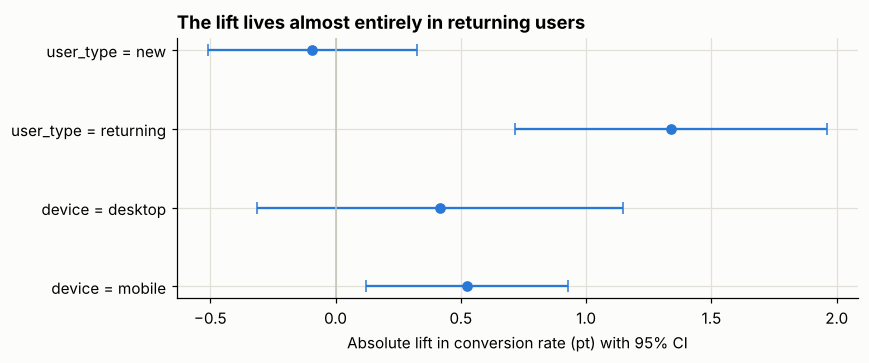

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.4))
y = np.arange(len(seg))
ax.errorbar((seg["cr_B_%"] - seg["cr_A_%"]), y, xerr=[(seg["cr_B_%"] - seg["cr_A_%"]) - seg["ci_low_pt"], seg["ci_high_pt"] - (seg["cr_B_%"] - seg["cr_A_%"])],
            fmt="o", color=BLUE, ecolor=BLUE, capsize=4)
ax.axvline(0, color="#c3c2b7", lw=1)
ax.set_yticks(y); ax.set_yticklabels(seg.index); ax.invert_yaxis()
ax.set_xlabel("Absolute lift in conversion rate (pt) with 95% CI")
ax.set_title("The lift lives almost entirely in returning users")
plt.tight_layout()

**Returning users: +36% relative (p < 0.0001). New users: −3%, indistinguishable from zero.**
That matches the mechanism — saved-address autofill and one-page flow remove friction that only
returning customers experienced. Mobile clears the adjusted bar on its own (+18%) and desktop does
not, but the two intervals overlap almost completely — there is no evidence the effect *differs*
by device, only that the mobile sample is 2.6× larger.

This is a finding to act on, not just a footnote: for new users the redesign did nothing, so the
new-user checkout experience is still an open problem.

## 6. Exploratory: novelty effect?
Redesigns often win in week 1 because they are *different*, then fade. Check lift by week.

In [20]:
ab["week"] = (ab["exposure_date"] - ab["exposure_date"].min()).dt.days // 7 + 1
wk = ab.groupby(["week", "variant"])["converted"].mean().unstack() * 100
wk["rel_lift_%"] = 100 * (wk["B"] / wk["A"] - 1)
wk.round(2)

variant,A,B,rel_lift_%
week,,,
1,3.00,3.89,29.81
2,3.35,3.45,2.98
3,3.14,3.65,16.27


Week-1 lift (~+30%) is higher than weeks 2–3 (+3%, +16%), which *could* be novelty — but with
~6.5k users per variant per week the weekly estimates are noisy and the pattern is not
monotonic. Not conclusive; it becomes a post-launch monitoring item rather than a reason to hold.

## Decision and recommendation

**Ship variant B.** The primary metric moved +15.9% (p = 0.006), revenue per user moved with it,
and no guardrail failed.

Three things go into the launch note:

1. **The lift is a returning-user lift.** Budget the new-user checkout as a separate project; do
   not expect this change to improve first-purchase conversion.
2. **Monitor for four weeks post-launch** on the week-over-week conversion of returning users.
   If it decays toward the control rate, the week-1 novelty signal was real.
3. **Next test should be powered for the segment that matters.** If the question is "does this
   help new users", a 15% MDE on a 2.7% baseline needs ~30k new users per arm — plan for it.

What I would *not* claim from this test: anything about basket size (no effect detected), or
about desktop users specifically (interval spans zero).